# Disaster Damage Assessment from Pre- and Post-Disaster Satellite Images Using SAM2 and Swin-Tiny

This notebook is the main workflow for disaster damage assessment with the xView2/xBD dataset.

The task is to compare pre-disaster and post-disaster satellite image crops for each building and classify damage into:

- no-damage
- minor-damage
- major-damage
- destroyed

The workflow uses two components:

1. **SAM2-assisted building localization** for interactive or prompt-based building region extraction.
2. **Swin Transformer-Tiny damage classification** using paired pre-disaster and post-disaster building crops.

Swin-Tiny is used because its hierarchical shifted-window attention can model local damage cues and surrounding context in satellite crop pairs.


## 1. Imports and Configuration

Run this section first. Heavy work is disabled by default so the notebook is safe to execute from top to bottom.


In [89]:
from __future__ import annotations

import json
import math
import os
import pickle
import random
import re
import sys
import time
import warnings
from collections import Counter
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageDraw
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import swin_t, Swin_T_Weights
from tqdm.auto import tqdm

try:
    from shapely import wkt
except Exception:
    wkt = None

try:
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    SAM2_AVAILABLE = True
except Exception as exc:
    SAM2_AVAILABLE = False
    SAM2_IMPORT_ERROR = exc

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print(f"Python version: {sys.version.split()[0]}")
print(f"torch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"PyTorch CUDA version: {torch.version.cuda}")
print(f"Device: {device}")
print(f"GPU count: {torch.cuda.device_count()}")
if device.type == "cuda":
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: CUDA is not available. Training will be very slow on CPU.")
print(f"cuDNN enabled: {torch.backends.cudnn.enabled}")
print(f"cuDNN benchmark: {torch.backends.cudnn.benchmark}")
print(f"SAM2 import available: {SAM2_AVAILABLE}")
if not SAM2_AVAILABLE:
    print(f"SAM2 import warning: {SAM2_IMPORT_ERROR}")


Python version: 3.10.11
torch version: 2.11.0+cu126
CUDA available: True
PyTorch CUDA version: 12.6
Device: cuda
GPU count: 1
GPU name: NVIDIA GeForce RTX 4060 Ti
cuDNN enabled: True
cuDNN benchmark: True
SAM2 import available: False
SAM2 import warning: No module named 'sam2'


In [ ]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Find the project root even when the notebook is launched from notebooks/."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "train_data").exists() and (candidate / "test_data").exists():
            return candidate
    return start

PROJECT_ROOT = find_project_root()

def resolve_xbd_split_dir(path_like: str | Path, split_name: str) -> Path:
    """Accept either the split folder itself or its parent folder.

    Examples that both work for test:
    - Path("test_data/test")
    - Path("test_data")
    """
    path = Path(path_like)
    if not path.is_absolute():
        path = PROJECT_ROOT / path
    if (path / "images").exists() and (path / "labels").exists():
        return path
    nested = path / split_name
    if (nested / "images").exists() and (nested / "labels").exists():
        return nested
    return path

# Your dataset folders. These resolve correctly from either the project root or notebooks/.
TRAIN_DIR = resolve_xbd_split_dir(Path("train_data/train"), "train")
TEST_DIR = resolve_xbd_split_dir(Path("test_data"), "test")

print(f"Notebook working directory: {Path.cwd()}")
print(f"Resolved PROJECT_ROOT: {PROJECT_ROOT}")
print(f"Resolved TRAIN_DIR   : {TRAIN_DIR}")
print(f"Resolved TEST_DIR    : {TEST_DIR}")
print(f"TRAIN_DIR exists     : {TRAIN_DIR.exists()}")
print(f"TEST_DIR exists      : {TEST_DIR.exists()}")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CROPS_DIR = PROCESSED_DIR / "crops"
SPLITS_DIR = PROCESSED_DIR / "splits"
RUNS_DIR = PROJECT_ROOT / "runs"
CHECKPOINTS_DIR = RUNS_DIR / "checkpoints"
PICKLES_DIR = RUNS_DIR / "pickles"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
QUALITATIVE_DIR = FIGURES_DIR / "qualitative_results"

for path in [PROCESSED_DIR, CROPS_DIR, SPLITS_DIR, RUNS_DIR, CHECKPOINTS_DIR, PICKLES_DIR, REPORTS_DIR, FIGURES_DIR, QUALITATIVE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Heavy stages are off by default. Turn them on manually when you are ready.
RUN_MASK_GENERATION = False
RUN_UNET_TRAINING = False
RUN_CROP_GENERATION = False
RUN_CLASSIFIER_TRAINING = False
RUN_SAM2_INFERENCE = False

# Development controls.
FAST_DEV_RUN = False          # Tiny subset for quick debugging.
BALANCED_SUBSET = True       # Cap samples per class for faster balanced experiments.
MAX_SAMPLES_PER_CLASS = 10000

# Swin-Tiny training defaults. For a final run, use FAST_DEV_RUN=False and increase EPOCHS.
EPOCHS = 15
BATCH_SIZE = 16
IMG_SIZE = 224
FREEZE_EPOCHS = 2
PATIENCE = 5
NUM_WORKERS = 0             # Windows notebooks are usually more stable with 0 workers.
LABEL_SMOOTHING = 0.05

MODEL_NAME = "swin_tiny"
CLASS_NAMES = ["no-damage", "minor-damage", "major-damage", "destroyed"]
DAMAGE_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
ID_TO_DAMAGE = {idx: name for name, idx in DAMAGE_TO_ID.items()}

with (REPORTS_DIR / "class_mapping.json").open("w", encoding="utf-8") as f:
    json.dump({"damage_to_id": DAMAGE_TO_ID, "id_to_damage": ID_TO_DAMAGE}, f, indent=2)

with (REPORTS_DIR / "training_config.json").open("w", encoding="utf-8") as f:
    json.dump({
        "model_name": MODEL_NAME,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "img_size": IMG_SIZE,
        "freeze_epochs": FREEZE_EPOCHS,
        "fast_dev_run": FAST_DEV_RUN,
        "balanced_subset": BALANCED_SUBSET,
        "max_samples_per_class": MAX_SAMPLES_PER_CLASS,
        "device": str(device),
    }, f, indent=2)


## 2. Dataset Inspection

The expected project structure is:

- train_data/train/images
- train_data/train/labels
- train_data/train/targets
- test_data/test/images
- test_data/test/labels
- test_data/test/targets


In [91]:
def list_files(folder: Path, patterns: Sequence[str]) -> List[Path]:
    files = []
    if not folder.exists():
        return files
    for pattern in patterns:
        files.extend(folder.glob(pattern))
    return sorted(set(files))

def inspect_split(split_dir: Path) -> Dict[str, List[Path]]:
    images = list_files(split_dir / "images", ["*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff"])
    labels = list_files(split_dir / "labels", ["*.json"])
    targets = list_files(split_dir / "targets", ["*.json"])
    print(f"\n{split_dir}")
    print(f"  images : {len(images)}")
    print(f"  labels : {len(labels)}")
    print(f"  targets: {len(targets)}")
    print("  example images:", [p.name for p in images[:5]])
    print("  example labels:", [p.name for p in labels[:5]])
    print("  example targets:", [p.name for p in targets[:5]])
    return {"images": images, "labels": labels, "targets": targets}

train_inventory = inspect_split(TRAIN_DIR)
test_inventory = inspect_split(TEST_DIR)



D:\Deeplearning project\train_data\train
  images : 5598
  labels : 5598
  targets: 0
  example images: ['guatemala-volcano_00000000_post_disaster.png', 'guatemala-volcano_00000000_pre_disaster.png', 'guatemala-volcano_00000001_post_disaster.png', 'guatemala-volcano_00000001_pre_disaster.png', 'guatemala-volcano_00000002_post_disaster.png']
  example labels: ['guatemala-volcano_00000000_post_disaster.json', 'guatemala-volcano_00000000_pre_disaster.json', 'guatemala-volcano_00000001_post_disaster.json', 'guatemala-volcano_00000001_pre_disaster.json', 'guatemala-volcano_00000002_post_disaster.json']
  example targets: []

D:\Deeplearning project\test_data\test
  images : 1866
  labels : 1866
  targets: 0
  example images: ['guatemala-volcano_00000003_post_disaster.png', 'guatemala-volcano_00000003_pre_disaster.png', 'guatemala-volcano_00000005_post_disaster.png', 'guatemala-volcano_00000005_pre_disaster.png', 'guatemala-volcano_00000009_post_disaster.png']
  example labels: ['guatemala-

## 3. xBD Annotation Parser and Pair Matching

These helpers parse polygon annotations, damage labels, and pre/post image pairs. Unknown or unclassified labels are ignored for classifier training.


In [121]:
def load_json(path: Path) -> dict:
    with Path(path).open("r", encoding="utf-8") as f:
        return json.load(f)

def normalize_stem(stem: str) -> str:
    return stem.replace("_pre_disaster", "").replace("_post_disaster", "")

def match_pre_post_pairs(images_dir: Path) -> List[Tuple[Path, Path, str]]:
    images = list_files(images_dir, ["*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff"])
    pre_images = [p for p in images if "pre_disaster" in p.stem]
    post_by_key = {normalize_stem(p.stem): p for p in images if "post_disaster" in p.stem}
    pairs = []
    for pre in pre_images:
        key = normalize_stem(pre.stem)
        post = post_by_key.get(key)
        if post is not None:
            pairs.append((pre, post, key))
    return sorted(pairs, key=lambda x: x[2])

def find_annotation_file(
    image_path: Path,
    labels_dir: Path,
    targets_dir: Optional[Path] = None,
    prefer_post: bool = False,
    allow_fallback: bool = False,
) -> Optional[Path]:
    search_dirs = []
    if prefer_post and targets_dir is not None:
        search_dirs.append(targets_dir)
    search_dirs.append(labels_dir)
    if not prefer_post and targets_dir is not None:
        search_dirs.append(targets_dir)

    wanted = "post_disaster" if prefer_post else "pre_disaster"
    opposite = "pre_disaster" if prefer_post else "post_disaster"
    stem = image_path.stem

    candidates = []
    for folder in search_dirs:
        if folder and folder.exists():
            candidates.extend(sorted(folder.glob("*.json")))

    def valid(path: Path) -> bool:
        if wanted in path.stem:
            return True
        if opposite in path.stem:
            return allow_fallback
        return True

    exact = [p for p in candidates if p.stem == stem and valid(p)]
    if exact:
        return exact[0]

    replacements = [stem.replace("pre_disaster", "post_disaster"), stem.replace("post_disaster", "pre_disaster")]
    for repl in replacements:
        hits = [p for p in candidates if p.stem == repl and valid(p)]
        if hits:
            return hits[0]

    key = normalize_stem(stem)
    preferred = [p for p in candidates if key in normalize_stem(p.stem) and wanted in p.stem]
    if preferred:
        return preferred[0]

    if allow_fallback:
        fallback = [p for p in candidates if key in normalize_stem(p.stem)]
        if fallback:
            return fallback[0]
    return None

def parse_wkt_polygon(wkt_string: str) -> List[Tuple[float, float]]:
    if not isinstance(wkt_string, str) or not wkt_string:
        return []
    if wkt is not None:
        try:
            geom = wkt.loads(wkt_string)
            if geom.geom_type == "Polygon":
                return [(float(x), float(y)) for x, y in list(geom.exterior.coords)]
        except Exception:
            pass
    nums = re.findall(r"[-+]?\d*\.?\d+", wkt_string)
    values = [float(x) for x in nums]
    return list(zip(values[0::2], values[1::2]))

def polygon_to_bbox(polygon: Sequence[Tuple[float, float]]) -> Optional[Tuple[int, int, int, int]]:
    if len(polygon) < 3:
        return None
    xs = [p[0] for p in polygon]
    ys = [p[1] for p in polygon]
    return int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))

def clip_bbox(bbox: Tuple[int, int, int, int], width: int, height: int, pad: int = 2) -> Optional[Tuple[int, int, int, int]]:
    x1, y1, x2, y2 = bbox
    x1 = max(0, min(width - 1, x1 - pad))
    y1 = max(0, min(height - 1, y1 - pad))
    x2 = max(0, min(width, x2 + pad))
    y2 = max(0, min(height, y2 + pad))
    if x2 <= x1 or y2 <= y1:
        return None
    return x1, y1, x2, y2

def annotation_features(annotation: dict) -> List[dict]:
    features = annotation.get("features", {})
    if isinstance(features, dict):
        return features.get("xy", []) or features.get("lng_lat", []) or []
    if isinstance(features, list):
        return features
    return []

def extract_buildings(annotation_path: Path, image_size: Tuple[int, int], require_damage: bool = True) -> List[dict]:
    annotation = load_json(annotation_path)
    width, height = image_size
    rows = []
    for item in annotation_features(annotation):
        props = item.get("properties", {})
        subtype = str(props.get("subtype", "")).strip()
        damage = subtype if subtype in DAMAGE_TO_ID else None
        if require_damage and damage is None:
            continue
        wkt_string = item.get("wkt") or props.get("wkt")
        polygon = parse_wkt_polygon(wkt_string)
        bbox = polygon_to_bbox(polygon)
        if bbox is None:
            continue
        bbox = clip_bbox(bbox, width, height)
        if bbox is None:
            continue
        rows.append({
            "polygon": polygon,
            "bbox": bbox,
            "label_name": damage,
            "label": DAMAGE_TO_ID[damage] if damage is not None else -1,
        })
    return rows

pairs = match_pre_post_pairs(TRAIN_DIR / "images")
print(f"Matched training pre/post pairs: {len(pairs)}")
for pre, post, key in pairs[:10]:
    pre_ann = find_annotation_file(pre, TRAIN_DIR / "labels", TRAIN_DIR / "targets", prefer_post=False)
    post_ann = find_annotation_file(post, TRAIN_DIR / "labels", TRAIN_DIR / "targets", prefer_post=True)
    print(f"\nPair: {key}")
    print(f"  pre image : {pre}")
    print(f"  pre ann   : {pre_ann}")
    print(f"  post image: {post}")
    print(f"  post ann  : {post_ann}")
    if pre_ann is None:
        warnings.warn(f"Missing pre annotation for {pre.name}")
    if post_ann is None:
        warnings.warn(f"Missing post/target annotation for {post.name}")


Matched training pre/post pairs: 2799

Pair: guatemala-volcano_00000000
  pre image : D:\Deeplearning project\train_data\train\images\guatemala-volcano_00000000_pre_disaster.png
  pre ann   : D:\Deeplearning project\train_data\train\labels\guatemala-volcano_00000000_pre_disaster.json
  post image: D:\Deeplearning project\train_data\train\images\guatemala-volcano_00000000_post_disaster.png
  post ann  : D:\Deeplearning project\train_data\train\labels\guatemala-volcano_00000000_post_disaster.json

Pair: guatemala-volcano_00000001
  pre image : D:\Deeplearning project\train_data\train\images\guatemala-volcano_00000001_pre_disaster.png
  pre ann   : D:\Deeplearning project\train_data\train\labels\guatemala-volcano_00000001_pre_disaster.json
  post image: D:\Deeplearning project\train_data\train\images\guatemala-volcano_00000001_post_disaster.png
  post ann  : D:\Deeplearning project\train_data\train\labels\guatemala-volcano_00000001_post_disaster.json

Pair: guatemala-volcano_00000002
  pr

## 4. Visual Inspection


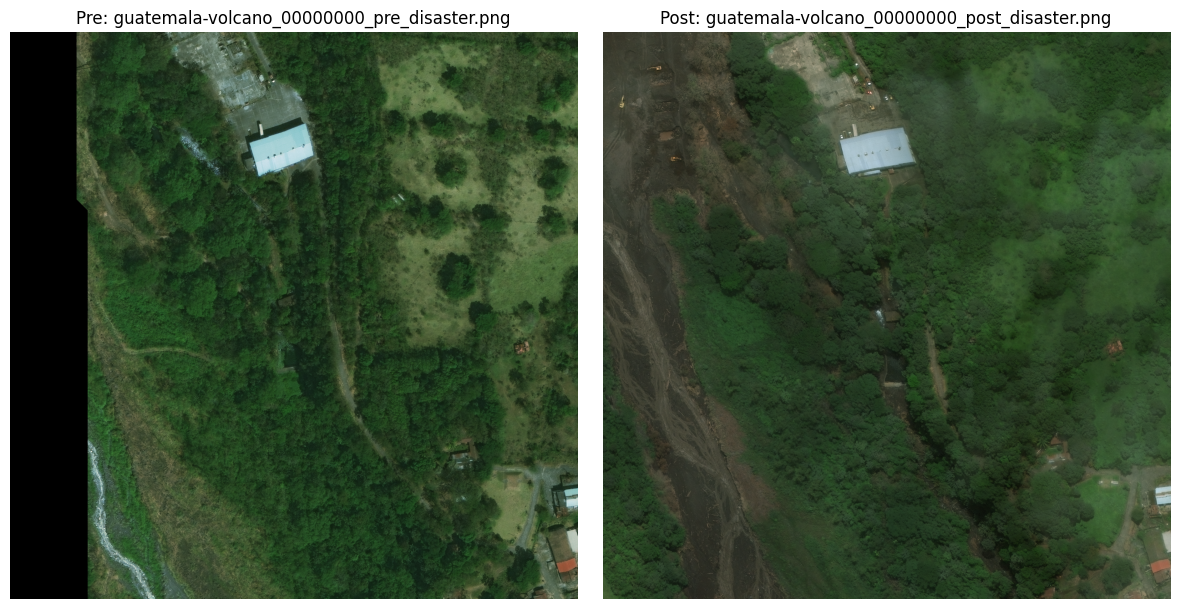

Example annotation: D:\Deeplearning project\train_data\train\labels\guatemala-volcano_00000000_post_disaster.json
Top-level keys: ['features', 'metadata']
Damage labels: ['no-damage', 'minor-damage', 'major-damage', 'destroyed']


In [122]:
def show_example_pair(split_dir: Path) -> None:
    pairs = match_pre_post_pairs(split_dir / "images")
    if not pairs:
        print("No pre/post pair found.")
        return
    pre, post, key = pairs[0]
    pre_img = Image.open(pre).convert("RGB")
    post_img = Image.open(post).convert("RGB")
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(pre_img)
    axes[0].set_title(f"Pre: {pre.name}")
    axes[1].imshow(post_img)
    axes[1].set_title(f"Post: {post.name}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    ann = find_annotation_file(post, split_dir / "labels", split_dir / "targets", prefer_post=True)
    if ann:
        data = load_json(ann)
        print(f"Example annotation: {ann}")
        print("Top-level keys:", list(data.keys()))
        print("Damage labels:", CLASS_NAMES)

show_example_pair(TRAIN_DIR)


## 5. Ground-Truth Crop Generation for Swin-Tiny Training

SAM2 is used for inference-time building localization. During supervised training, xBD ground-truth polygons provide reliable building boxes for creating paired pre/post crops.


In [96]:
def split_pairs(pairs: List[Tuple[Path, Path, str]], test_size: float = 0.15, val_size: float = 0.15):
    if len(pairs) < 3:
        return pairs, [], []
    train_pairs, temp_pairs = train_test_split(pairs, test_size=test_size + val_size, random_state=SEED)
    relative_val = val_size / (test_size + val_size)
    val_pairs, test_pairs = train_test_split(temp_pairs, test_size=1 - relative_val, random_state=SEED)
    return train_pairs, val_pairs, test_pairs

def crop_and_save(img: Image.Image, bbox: Tuple[int, int, int, int], out_path: Path, size: int = IMG_SIZE) -> None:
    out_path.parent.mkdir(parents=True, exist_ok=True)
    crop = img.crop(bbox).resize((size, size), Image.BILINEAR)
    crop.save(out_path)

def generate_crop_metadata(split_name: str, split_dir: Path, pair_list: List[Tuple[Path, Path, str]], output_dir: Path) -> pd.DataFrame:
    rows = []
    crop_image_dir = output_dir / "images" / split_name
    for pre_path, post_path, image_id in tqdm(pair_list, desc=f"Generating {split_name} crops"):
        post_ann = find_annotation_file(post_path, split_dir / "labels", split_dir / "targets", prefer_post=True)
        if post_ann is None:
            continue
        pre_img = Image.open(pre_path).convert("RGB")
        post_img = Image.open(post_path).convert("RGB")
        width, height = post_img.size
        buildings = extract_buildings(post_ann, (width, height), require_damage=True)
        disaster_name = image_id.split("_")[0]
        for idx, building in enumerate(buildings):
            label = int(building["label"])
            label_name = str(building["label_name"])
            bbox = tuple(building["bbox"])
            pre_crop = crop_image_dir / f"{image_id}_{idx:05d}_pre.png"
            post_crop = crop_image_dir / f"{image_id}_{idx:05d}_post.png"
            crop_and_save(pre_img, bbox, pre_crop)
            crop_and_save(post_img, bbox, post_crop)
            rows.append({
                "pre_crop_path": str(pre_crop),
                "post_crop_path": str(post_crop),
                "label": label,
                "label_name": label_name,
                "disaster_name": disaster_name,
                "image_id": image_id,
                "bbox_x1": bbox[0],
                "bbox_y1": bbox[1],
                "bbox_x2": bbox[2],
                "bbox_y2": bbox[3],
            })
    df = pd.DataFrame(rows)
    csv_path = output_dir / f"{split_name}.csv"
    df.to_csv(csv_path, index=False)
    print(f"Saved {len(df)} rows to {csv_path}")
    return df

if RUN_CROP_GENERATION:
    train_pairs_all = match_pre_post_pairs(TRAIN_DIR / "images")
    train_pairs, val_pairs, internal_test_pairs = split_pairs(train_pairs_all)
    external_test_pairs = match_pre_post_pairs(TEST_DIR / "images")
    test_pairs = external_test_pairs if external_test_pairs else internal_test_pairs
    generate_crop_metadata("train", TRAIN_DIR, train_pairs, CROPS_DIR)
    generate_crop_metadata("val", TRAIN_DIR, val_pairs, CROPS_DIR)
    generate_crop_metadata("test", TEST_DIR if external_test_pairs else TRAIN_DIR, test_pairs, CROPS_DIR)
else:
    print("Crop generation skipped. Set RUN_CROP_GENERATION=True when crops need to be rebuilt.")


Generating train crops: 100%|██████████| 1959/1959 [38:50<00:00,  1.19s/it]  


Saved 111758 rows to D:\Deeplearning project\data\processed\crops\train.csv


Generating val crops: 100%|██████████| 420/420 [07:11<00:00,  1.03s/it]


Saved 22443 rows to D:\Deeplearning project\data\processed\crops\val.csv


Generating test crops: 100%|██████████| 933/933 [15:20<00:00,  1.01it/s]  


Saved 53850 rows to D:\Deeplearning project\data\processed\crops\test.csv


## 6. Crop CSV Checks and Balanced Subsets


train: 111758 samples
label_name
no-damage       80317
minor-damage    10974
destroyed       10309
major-damage    10158
train: crop paths verified.
val: 22443 samples
label_name
no-damage       17009
major-damage     1952
minor-damage     1877
destroyed        1605
val: crop paths verified.
test: 53850 samples
label_name
no-damage       41427
minor-damage     4798
major-damage     3850
destroyed        3775
test: crop paths verified.

train before: {'no-damage': 80317, 'minor-damage': 10974, 'destroyed': 10309, 'major-damage': 10158}
train after : {'destroyed': 10000, 'minor-damage': 10000, 'major-damage': 10000, 'no-damage': 10000}
Saved D:\Deeplearning project\data\processed\crops\train_balanced.csv

val before: {'no-damage': 17009, 'major-damage': 1952, 'minor-damage': 1877, 'destroyed': 1605}
val after : {'no-damage': 10000, 'major-damage': 1952, 'minor-damage': 1877, 'destroyed': 1605}
Saved D:\Deeplearning project\data\processed\crops\val_balanced.csv

test before: {'no-damage':

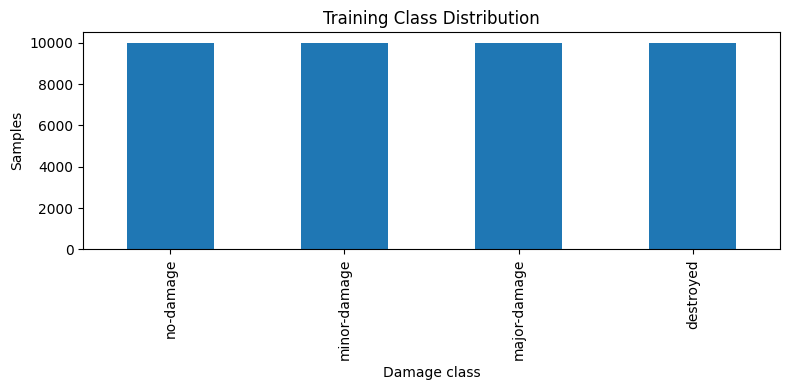

In [132]:
def load_crop_csv(split: str) -> Optional[pd.DataFrame]:
    path = CROPS_DIR / f"{split}.csv"
    if not path.exists():
        print(f"Missing {path}")
        return None
    df = pd.read_csv(path)
    print(f"{split}: {len(df)} samples")
    print(df["label_name"].value_counts(dropna=False).to_string())
    return df

def resolve_crop_path(value) -> Path:
    """Resolve crop paths saved either relative to project root or relative to CROPS_DIR."""
    p = Path(str(value))
    candidates = []
    if p.is_absolute():
        candidates.append(p)
    else:
        candidates.extend([PROJECT_ROOT / p, CROPS_DIR / p])
    for candidate in candidates:
        if candidate.exists():
            return candidate
    return candidates[-1] if candidates else p

def repair_crop_paths(df: Optional[pd.DataFrame], split: str) -> Optional[pd.DataFrame]:
    if df is None or df.empty:
        return df
    df = df.copy()
    missing_examples = []
    for column in ["pre_crop_path", "post_crop_path"]:
        resolved = df[column].map(resolve_crop_path)
        missing_mask = ~resolved.map(lambda p: p.exists())
        if missing_mask.any():
            missing_examples.extend(resolved[missing_mask].head(3).astype(str).tolist())
        df[column] = resolved.map(lambda p: str(p))
    if missing_examples:
        warnings.warn(
            f"{split}: some crop files are still missing after path repair. "
            f"Examples: {missing_examples[:3]}"
        )
    else:
        print(f"{split}: crop paths verified.")
    return df

def auto_generate_missing_crops() -> None:
    required = [CROPS_DIR / f"{split}.csv" for split in ["train", "val", "test"]]
    if all(path.exists() for path in required):
        return
    print("One or more crop CSVs are missing, so the notebook will create them from xBD annotations now.")
    train_pairs_all = match_pre_post_pairs(TRAIN_DIR / "images")
    if not train_pairs_all:
        raise RuntimeError("No train pre/post pairs found. Check TRAIN_DIR.")
    train_pairs, val_pairs, internal_test_pairs = split_pairs(train_pairs_all)
    external_test_pairs = match_pre_post_pairs(TEST_DIR / "images")
    test_pairs = external_test_pairs if external_test_pairs else internal_test_pairs
    if not (CROPS_DIR / "train.csv").exists():
        generate_crop_metadata("train", TRAIN_DIR, train_pairs, CROPS_DIR)
    if not (CROPS_DIR / "val.csv").exists():
        generate_crop_metadata("val", TRAIN_DIR, val_pairs, CROPS_DIR)
    if not (CROPS_DIR / "test.csv").exists():
        generate_crop_metadata("test", TEST_DIR if external_test_pairs else TRAIN_DIR, test_pairs, CROPS_DIR)

auto_generate_missing_crops()
crop_frames = {split: repair_crop_paths(load_crop_csv(split), split) for split in ["train", "val", "test"]}

def make_balanced_subset(df: pd.DataFrame, split: str, max_per_class: int) -> pd.DataFrame:
    if df is None or df.empty:
        return pd.DataFrame()
    before = df["label_name"].value_counts().to_dict()
    parts = []
    for _, group in df.groupby("label", group_keys=False):
        parts.append(group.sample(n=min(len(group), max_per_class), random_state=SEED))
    balanced = pd.concat(parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    after = balanced["label_name"].value_counts().to_dict()
    out_path = CROPS_DIR / f"{split}_balanced.csv"
    balanced.to_csv(out_path, index=False)
    print(f"\n{split} before: {before}")
    print(f"{split} after : {after}")
    print(f"Saved {out_path}")
    return balanced

def stratified_fast_subset(df: pd.DataFrame, split: str) -> pd.DataFrame:
    if df is None or df.empty:
        return pd.DataFrame()
    per_class = {"train": 125, "val": 25, "test": 25}.get(split, 25)
    parts = []
    for _, group in df.groupby("label", group_keys=False):
        parts.append(group.sample(n=min(len(group), per_class), random_state=SEED))
    subset = pd.concat(parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    print(f"{split} FAST_DEV_RUN subset: {len(subset)} samples")
    print(subset["label_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_string())
    return subset

if BALANCED_SUBSET:
    crop_frames = {
        split: make_balanced_subset(df, split, MAX_SAMPLES_PER_CLASS)
        for split, df in crop_frames.items()
        if df is not None
    }

if FAST_DEV_RUN:
    print("\nFAST_DEV_RUN is enabled: using a small stratified real-data subset for debugging.")
    print("Accuracy from FAST_DEV_RUN is only a pipeline check. Use FAST_DEV_RUN=False for final accuracy.")
    for split in ["train", "val", "test"]:
        if split in crop_frames and crop_frames[split] is not None and not crop_frames[split].empty:
            crop_frames[split] = stratified_fast_subset(crop_frames[split], split)
    EPOCHS = min(EPOCHS, 3)

if "train" in crop_frames and crop_frames["train"] is not None and not crop_frames["train"].empty:
    counts = crop_frames["train"]["label_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    ax = counts.plot(kind="bar", figsize=(8, 4), title="Training Class Distribution")
    ax.set_xlabel("Damage class")
    ax.set_ylabel("Samples")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=200)
    plt.show()


## 7. Swin-Tiny Crop Dataset and DataLoaders


In [133]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class PairedCropDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, train: bool, img_size: int = IMG_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.train = train
        self.img_size = img_size
        self.resize = transforms.Resize((img_size, img_size))
        self.color = transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.03)
        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

    def __len__(self):
        return len(self.frame)

    def _transform_pair(self, pre: Image.Image, post: Image.Image):
        pre = self.resize(pre)
        post = self.resize(post)
        if self.train:
            if random.random() < 0.5:
                pre = transforms.functional.hflip(pre)
                post = transforms.functional.hflip(post)
            if random.random() < 0.5:
                pre = transforms.functional.vflip(pre)
                post = transforms.functional.vflip(post)
            angle = random.uniform(-15, 15)
            pre = transforms.functional.rotate(pre, angle)
            post = transforms.functional.rotate(post, angle)
            pre = self.color(pre)
            post = self.color(post)
        pre = self.normalize(self.to_tensor(pre))
        post = self.normalize(self.to_tensor(post))
        return pre, post

    def __getitem__(self, idx: int):
        row = self.frame.iloc[idx]
        pre_path = resolve_crop_path(row["pre_crop_path"])
        post_path = resolve_crop_path(row["post_crop_path"])
        if not pre_path.exists() or not post_path.exists():
            raise FileNotFoundError(f"Missing crop pair: pre={pre_path}, post={post_path}")
        pre = Image.open(pre_path).convert("RGB")
        post = Image.open(post_path).convert("RGB")
        pre_t, post_t = self._transform_pair(pre, post)
        label = torch.tensor(int(row["label"]), dtype=torch.long)
        return pre_t, post_t, label, str(row.get("image_id", idx))

def make_loader(split: str, train: bool) -> Optional[DataLoader]:
    df = crop_frames.get(split)
    if df is None or df.empty:
        print(f"No dataframe for {split}; loader not created.")
        return None
    dataset = PairedCropDataset(df, train=train)
    pin_memory = device.type == "cuda"
    persistent_workers = NUM_WORKERS > 0
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=train,
        num_workers=NUM_WORKERS,
        pin_memory=pin_memory,
        persistent_workers=persistent_workers,
    )
    print(f"{split}: samples={len(dataset)}, batch_size={BATCH_SIZE}, num_workers={NUM_WORKERS}, pin_memory={pin_memory}, batches={len(loader)}")
    return loader

train_loader = make_loader("train", train=True)
val_loader = make_loader("val", train=False)
test_loader = make_loader("test", train=False)

def diagnose_training_data() -> None:
    print("\nTraining-data diagnostic")
    if train_loader is None:
        print("Swin-Tiny is NOT ready to train: train_loader is None.")
        return
    print(f"Swin-Tiny will train on {len(train_loader.dataset)} real crop pairs.")
    print(f"Validation samples: {len(val_loader.dataset) if val_loader is not None else 0}")
    print(f"Test samples: {len(test_loader.dataset) if test_loader is not None else 0}")
    train_df = crop_frames.get("train")
    if train_df is not None and not train_df.empty:
        print("Train class distribution:")
        print(train_df["label_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_string())
        majority = train_df["label"].value_counts(normalize=True).max()
        print(f"Majority-class baseline accuracy on this training subset: {majority:.3f}")
        sample = train_df.iloc[0]
        print("Example resolved crop paths:")
        print("  pre :", resolve_crop_path(sample["pre_crop_path"]))
        print("  post:", resolve_crop_path(sample["post_crop_path"]))
    pre, post, labels, ids = next(iter(train_loader))
    print(f"First batch pre tensor : {tuple(pre.shape)}")
    print(f"First batch post tensor: {tuple(post.shape)}")
    print(f"First batch labels     : {labels.tolist()[:16]}")
    print(f"CUDA device            : {device}")

diagnose_training_data()


train: samples=40000, batch_size=16, num_workers=0, pin_memory=True, batches=2500
val: samples=15434, batch_size=16, num_workers=0, pin_memory=True, batches=965
test: samples=22423, batch_size=16, num_workers=0, pin_memory=True, batches=1402

Training-data diagnostic
Swin-Tiny will train on 40000 real crop pairs.
Validation samples: 15434
Test samples: 22423
Train class distribution:
label_name
no-damage       10000
minor-damage    10000
major-damage    10000
destroyed       10000
Majority-class baseline accuracy on this training subset: 0.250
Example resolved crop paths:
  pre : D:\Deeplearning project\data\processed\crops\images\train\hurricane-matthew_00000085_00007_pre.png
  post: D:\Deeplearning project\data\processed\crops\images\train\hurricane-matthew_00000085_00007_post.png
First batch pre tensor : (16, 3, 224, 224)
First batch post tensor: (16, 3, 224, 224)
First batch labels     : [0, 3, 1, 3, 0, 0, 0, 3, 2, 3, 1, 2, 1, 1, 1, 1]
CUDA device            : cuda


## 8. Swin Transformer-Tiny Damage Classifier

This is the only classifier in the notebook. It receives pre-disaster and post-disaster crops, extracts one shared Swin-Tiny feature vector for each crop, fuses the two features with their absolute difference, and predicts four damage classes.


In [134]:
class PretrainedSwinTinyDamageClassifier(nn.Module):
    def __init__(self, num_classes: int = 4, pretrained: bool = True, freeze_backbone: bool = True):
        super().__init__()
        weights = Swin_T_Weights.DEFAULT if pretrained else None
        self.backbone = swin_t(weights=weights)
        feature_dim = self.backbone.head.in_features
        self.backbone.head = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 3, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )
        if freeze_backbone:
            self.freeze_backbone()

    def freeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = False

    def unfreeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = True

    def forward_once(self, x):
        return self.backbone(x)

    def forward(self, pre_img, post_img):
        pre_features = self.forward_once(pre_img)
        post_features = self.forward_once(post_img)
        diff_features = torch.abs(pre_features - post_features)
        fused = torch.cat([pre_features, post_features, diff_features], dim=1)
        return self.classifier(fused)

def build_classifier(pretrained: bool = True, freeze_backbone: bool = True):
    return PretrainedSwinTinyDamageClassifier(num_classes=4, pretrained=pretrained, freeze_backbone=freeze_backbone)


In [135]:
# Optional dummy forward pass. It may download ImageNet weights the first time pretrained=True is used.
RUN_DUMMY_FORWARD = False
if RUN_DUMMY_FORWARD:
    dummy_model = build_classifier(pretrained=True, freeze_backbone=True).to(device)
    x1 = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device)
    x2 = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device)
    with torch.no_grad():
        out = dummy_model(x1, x2)
    assert out.shape == (2, 4)
    dummy_model.freeze_backbone()
    dummy_model.unfreeze_backbone()
    print("Swin-Tiny forward/freezing sanity check passed.")


## 9. Training Utilities

Best-only checkpointing is used. Training saves:

- runs/checkpoints/best_swin_tiny_damage.pt
- runs/pickles/best_swin_tiny_damage.pkl


In [136]:
def class_weights_from_frame(df: pd.DataFrame) -> torch.Tensor:
    counts = df["label"].value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0).values.astype(float)
    total = counts.sum()
    weights = total / (len(counts) * np.maximum(counts, 1.0))
    return torch.tensor(weights, dtype=torch.float32, device=device)

def metric_dict(y_true, y_pred) -> Dict[str, float]:
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "weighted_f1": weighted_f1,
    }

def build_optimizer_for_swin(model: PretrainedSwinTinyDamageClassifier, fine_tune: bool):
    if fine_tune:
        return torch.optim.AdamW([
            {"params": model.backbone.parameters(), "lr": 1e-5},
            {"params": model.classifier.parameters(), "lr": 1e-4},
        ], weight_decay=1e-4)
    return torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=1e-4)

def save_best_checkpoint(model, optimizer, scheduler, epoch, metrics, history):
    checkpoint = {
        "model_name": MODEL_NAME,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "metrics": metrics,
        "history": history,
        "class_mapping": {"damage_to_id": DAMAGE_TO_ID, "id_to_damage": ID_TO_DAMAGE},
        "config": {
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "freeze_epochs": FREEZE_EPOCHS,
            "label_smoothing": LABEL_SMOOTHING,
        },
    }
    pt_path = CHECKPOINTS_DIR / "best_swin_tiny_damage.pt"
    pkl_path = PICKLES_DIR / "best_swin_tiny_damage.pkl"
    torch.save(checkpoint, pt_path)
    with pkl_path.open("wb") as f:
        pickle.dump(checkpoint, f)
    return pt_path, pkl_path

def run_classifier_epoch(model, loader, criterion, optimizer=None, scaler=None, epoch=15, train=True):
    model.train(train)
    total_loss = 0.0
    y_true, y_pred = [], []
    desc = f"{'Train' if train else 'Val'} epoch {epoch}"
    iterator = tqdm(loader, desc=desc, leave=False)
    use_amp = device.type == "cuda"
    for pre, post, labels, _ in iterator:
        pre = pre.to(device, non_blocking=True)
        post = post.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if train:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(pre, post)
                loss = criterion(logits, labels)
            if train:
                scaler.scale(loss).backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
        total_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=1)
        y_true.extend(labels.detach().cpu().tolist())
        y_pred.extend(preds.detach().cpu().tolist())
        lr = optimizer.param_groups[0]["lr"] if optimizer is not None else 0
        iterator.set_postfix(loss=f"{loss.item():.4f}", lr=f"{lr:.2e}")
    metrics = metric_dict(y_true, y_pred)
    metrics["loss"] = total_loss / max(1, len(loader.dataset))
    return metrics


In [137]:
def train_swin_tiny():
    if train_loader is None or val_loader is None:
        raise RuntimeError("Missing train/val loaders. Generate or load crop CSVs first.")

    model = build_classifier(pretrained=True, freeze_backbone=True).to(device)
    class_weights = class_weights_from_frame(crop_frames["train"])
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
    optimizer = build_optimizer_for_swin(model, fine_tune=False)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, EPOCHS))
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    best_macro_f1 = -1.0
    best_epoch = 0
    patience_counter = 0
    history = []
    start = time.time()

    print("Starting classifier training for: swin_tiny")
    print(f"Training samples: {len(train_loader.dataset)} | validation samples: {len(val_loader.dataset)}")
    print(f"FAST_DEV_RUN={FAST_DEV_RUN}. For meaningful accuracy, set FAST_DEV_RUN=False and rerun Sections 6 onward.")
    try:
        for epoch in range(1, EPOCHS + 1):
            epoch_start = time.time()
            if epoch == FREEZE_EPOCHS + 1:
                model.unfreeze_backbone()
                optimizer = build_optimizer_for_swin(model, fine_tune=True)
                scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, EPOCHS - epoch + 1))
                print("Swin-Tiny backbone unfrozen for fine-tuning.")

            train_metrics = run_classifier_epoch(model, train_loader, criterion, optimizer, scaler, epoch, train=True)
            val_metrics = run_classifier_epoch(model, val_loader, criterion, epoch=epoch, train=False)
            scheduler.step()

            row = {
                "epoch": epoch,
                "train_loss": train_metrics["loss"],
                "val_loss": val_metrics["loss"],
                "val_accuracy": val_metrics["accuracy"],
                "val_macro_precision": val_metrics["macro_precision"],
                "val_macro_recall": val_metrics["macro_recall"],
                "val_macro_f1": val_metrics["macro_f1"],
                "val_weighted_f1": val_metrics["weighted_f1"],
                "lr": optimizer.param_groups[0]["lr"],
                "epoch_time": time.time() - epoch_start,
            }
            history.append(row)
            pd.DataFrame(history).to_csv(REPORTS_DIR / "training_log_swin_tiny.csv", index=False)

            if val_metrics["macro_f1"] > best_macro_f1:
                best_macro_f1 = val_metrics["macro_f1"]
                best_epoch = epoch
                pt_path, pkl_path = save_best_checkpoint(model, optimizer, scheduler, epoch, val_metrics, history)
                print(f"Saved best checkpoint: {pt_path}")
                print(f"Saved best pickle: {pkl_path}")
                patience_counter = 0
            else:
                patience_counter += 1

            elapsed = time.time() - start
            avg_epoch = elapsed / epoch
            remaining = avg_epoch * (EPOCHS - epoch)
            print(
                f"Epoch {epoch}/{EPOCHS} | time={row['epoch_time']:.1f}s | "
                f"train_loss={row['train_loss']:.4f} | val_loss={row['val_loss']:.4f} | "
                f"val_acc={row['val_accuracy']:.4f} | val_macro_f1={row['val_macro_f1']:.4f} | "
                f"best_macro_f1={best_macro_f1:.4f} | eta={remaining/60:.1f} min"
            )

            if patience_counter >= PATIENCE:
                print(f"Early stopping after {PATIENCE} epochs without validation macro F1 improvement.")
                break
    except KeyboardInterrupt:
        emergency = CHECKPOINTS_DIR / "interrupted_swin_tiny_damage.pt"
        torch.save({
            "model_name": MODEL_NAME,
            "epoch": len(history),
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
            "history": history,
            "best_metric": best_macro_f1,
        }, emergency)
        print(f"Training interrupted. Emergency checkpoint saved to: {emergency}")
        return model, history

    print("Finished classifier training for: swin_tiny")
    print(f"Best epoch: {best_epoch}, best validation macro F1: {best_macro_f1:.4f}")
    return model, history

if RUN_CLASSIFIER_TRAINING:
    trained_model, training_history = train_swin_tiny()
else:
    print("Classifier training skipped. Set RUN_CLASSIFIER_TRAINING=True when ready.")


Starting classifier training for: swin_tiny
Training samples: 40000 | validation samples: 15434
FAST_DEV_RUN=False. For meaningful accuracy, set FAST_DEV_RUN=False and rerun Sections 6 onward.


Saved best checkpoint: D:\Deeplearning project\runs\checkpoints\best_swin_tiny_damage.pt
Saved best pickle: D:\Deeplearning project\runs\pickles\best_swin_tiny_damage.pkl
Epoch 1/15 | time=1154.5s | train_loss=0.9712 | val_loss=0.9645 | val_acc=0.6388 | val_macro_f1=0.5710 | best_macro_f1=0.5710 | eta=269.4 min


Saved best checkpoint: D:\Deeplearning project\runs\checkpoints\best_swin_tiny_damage.pt
Saved best pickle: D:\Deeplearning project\runs\pickles\best_swin_tiny_damage.pkl
Epoch 2/15 | time=601.8s | train_loss=0.9048 | val_loss=0.9381 | val_acc=0.6439 | val_macro_f1=0.5862 | best_macro_f1=0.5862 | eta=190.3 min
Swin-Tiny backbone unfrozen for fine-tuning.


Saved best checkpoint: D:\Deeplearning project\runs\checkpoints\best_swin_tiny_damage.pt
Saved best pickle: D:\Deeplearning project\runs\pickles\best_swin_tiny_damage.pkl
Epoch 3/15 | time=735.2s | train_loss=0.8122 | val_loss=0.7954 | val_acc=0.7346 | val_macro_f1=0.6559 | best_macro_f1=0.6559 | eta=166.2 min


Saved best checkpoint: D:\Deeplearning project\runs\checkpoints\best_swin_tiny_damage.pt
Saved best pickle: D:\Deeplearning project\runs\pickles\best_swin_tiny_damage.pkl
Epoch 4/15 | time=743.2s | train_loss=0.7641 | val_loss=0.7866 | val_acc=0.7371 | val_macro_f1=0.6626 | best_macro_f1=0.6626 | eta=148.3 min


Saved best checkpoint: D:\Deeplearning project\runs\checkpoints\best_swin_tiny_damage.pt
Saved best pickle: D:\Deeplearning project\runs\pickles\best_swin_tiny_damage.pkl
Epoch 5/15 | time=745.0s | train_loss=0.7454 | val_loss=0.7670 | val_acc=0.7482 | val_macro_f1=0.6673 | best_macro_f1=0.6673 | eta=132.7 min


... (6 outputs left out)

Epoch 12/15 | time=753.0s | train_loss=0.6678 | val_loss=0.7571 | val_acc=0.7571 | val_macro_f1=0.6788 | best_macro_f1=0.6849 | eta=40.9 min


Epoch 13/15 | time=726.8s | train_loss=0.6642 | val_loss=0.7634 | val_acc=0.7540 | val_macro_f1=0.6725 | best_macro_f1=0.6849 | eta=27.0 min


Epoch 14/15 | time=728.7s | train_loss=0.6637 | val_loss=0.7683 | val_acc=0.7511 | val_macro_f1=0.6742 | best_macro_f1=0.6849 | eta=13.4 min


Epoch 15/15 | time=729.6s | train_loss=0.6596 | val_loss=0.7387 | val_acc=0.7634 | val_macro_f1=0.6791 | best_macro_f1=0.6849 | eta=0.0 min
Finished classifier training for: swin_tiny
Best epoch: 11, best validation macro F1: 0.6849


## 10. Load Checkpoint and Evaluate


Evaluating Swin-Tiny: 100%|██████████| 1402/1402 [06:53<00:00,  3.39it/s]


{'accuracy': 0.7775498372207109, 'macro_precision': 0.7533907516042821, 'macro_recall': 0.7682693667183363, 'macro_f1': 0.7575494405701129, 'weighted_f1': 0.7818894696974844}
              precision    recall  f1-score   support

   no-damage       0.91      0.82      0.86     10000
minor-damage       0.68      0.67      0.68      4798
major-damage       0.59      0.76      0.66      3850
   destroyed       0.83      0.83      0.83      3775

    accuracy                           0.78     22423
   macro avg       0.75      0.77      0.76     22423
weighted avg       0.79      0.78      0.78     22423



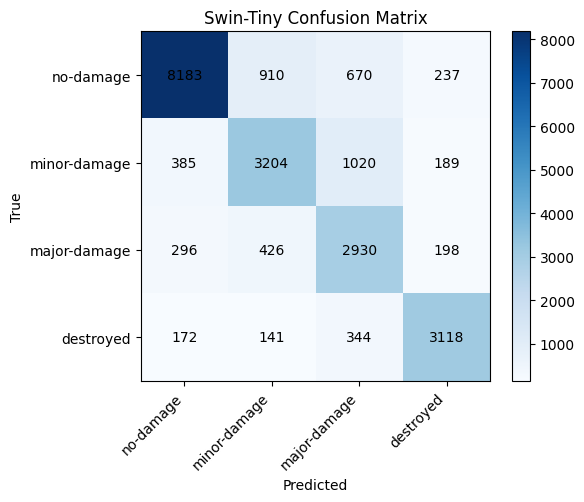

In [138]:
def load_swin_checkpoint(checkpoint_path: Path, map_device=device):
    state = torch.load(checkpoint_path, map_location=map_device)
    model = build_classifier(pretrained=False, freeze_backbone=False).to(map_device)
    model.load_state_dict(state["model_state_dict"])
    model.eval()
    return model, state

@torch.no_grad()
def evaluate_swin(checkpoint_path: Path, loader: Optional[DataLoader]):
    if loader is None:
        print("No test loader available.")
        return None
    if not checkpoint_path.exists():
        print(f"WARNING: checkpoint missing, skipping evaluation: {checkpoint_path}")
        return None
    model, state = load_swin_checkpoint(checkpoint_path)
    y_true, y_pred, confidences = [], [], []
    for pre, post, labels, _ in tqdm(loader, desc="Evaluating Swin-Tiny"):
        pre = pre.to(device, non_blocking=True)
        post = post.to(device, non_blocking=True)
        logits = model(pre, post)
        probs = torch.softmax(logits, dim=1)
        conf, pred = probs.max(dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(pred.cpu().tolist())
        confidences.extend(conf.cpu().tolist())

    metrics = metric_dict(y_true, y_pred)
    print(metrics)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

    results = pd.DataFrame([{
        "model_name": "swin_tiny",
        **metrics,
        "checkpoint_path": str(checkpoint_path),
        "pickle_path": str(PICKLES_DIR / "best_swin_tiny_damage.pkl"),
    }])
    results.to_csv(REPORTS_DIR / "classification_experiment_results.csv", index=False)

    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title("Swin-Tiny Confusion Matrix")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "confusion_matrix_swin_tiny.png", dpi=200)
    plt.show()
    return metrics, y_true, y_pred, confidences

evaluation_output = evaluate_swin(CHECKPOINTS_DIR / "best_swin_tiny_damage.pt", test_loader)


## 11. Metric and Training Curve Plots


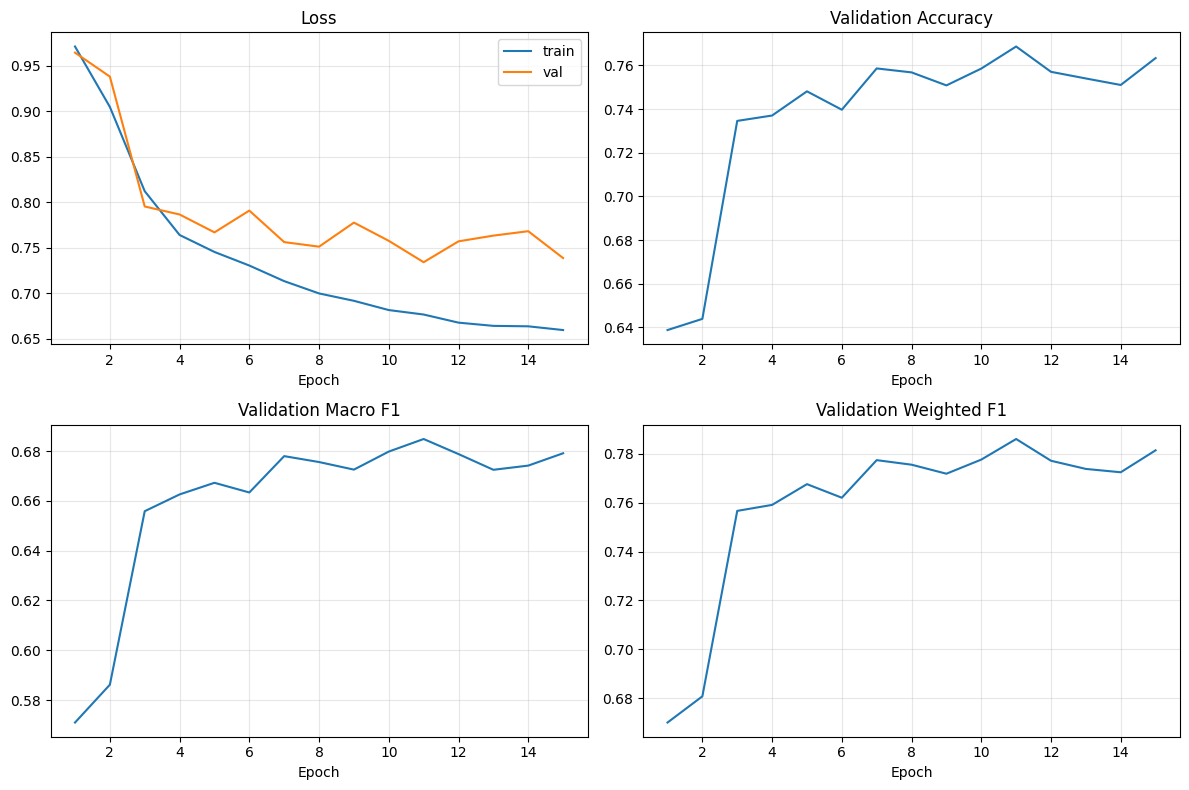

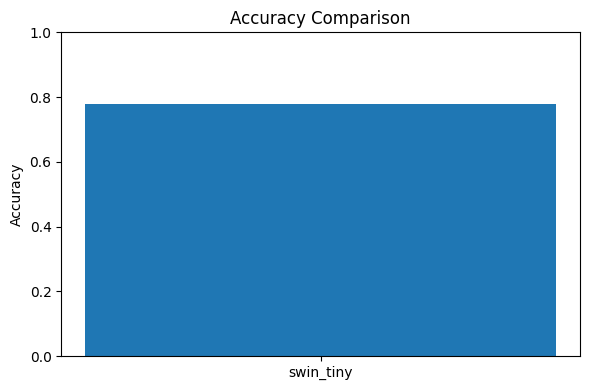

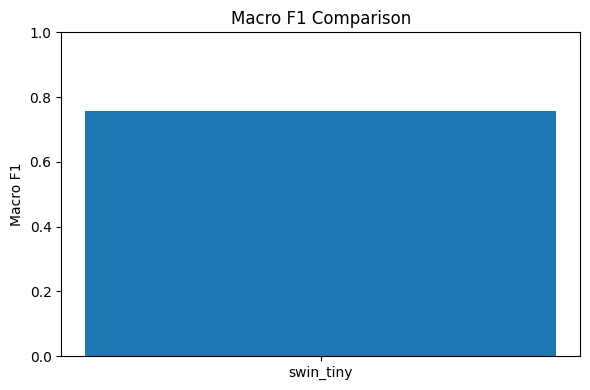

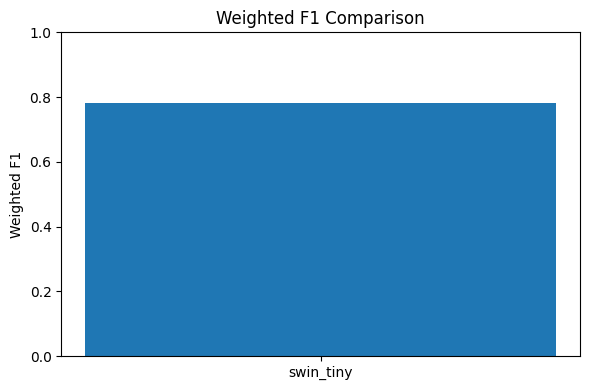

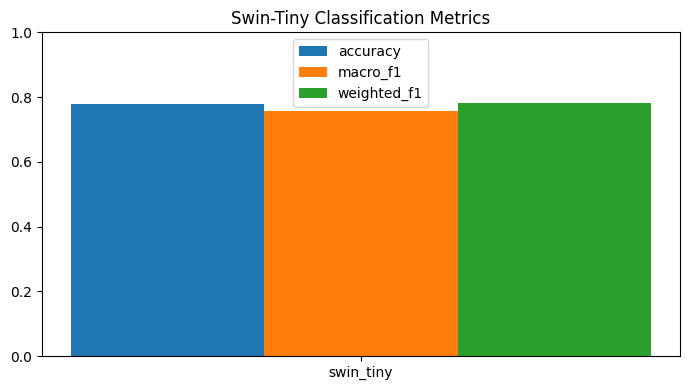

In [139]:
def plot_training_curves_from_log(log_path: Path):
    if not log_path.exists():
        print(f"Missing log: {log_path}")
        return
    hist = pd.read_csv(log_path)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].plot(hist["epoch"], hist["train_loss"], label="train")
    axes[0, 0].plot(hist["epoch"], hist["val_loss"], label="val")
    axes[0, 0].set_title("Loss")
    axes[0, 0].legend()
    axes[0, 1].plot(hist["epoch"], hist["val_accuracy"])
    axes[0, 1].set_title("Validation Accuracy")
    axes[1, 0].plot(hist["epoch"], hist["val_macro_f1"])
    axes[1, 0].set_title("Validation Macro F1")
    axes[1, 1].plot(hist["epoch"], hist["val_weighted_f1"])
    axes[1, 1].set_title("Validation Weighted F1")
    for ax in axes.ravel():
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "training_curves_swin_tiny.png", dpi=200)
    plt.show()

def plot_classification_bars(results_path: Path):
    if not results_path.exists():
        print(f"Missing results CSV: {results_path}")
        return
    df = pd.read_csv(results_path)
    if df.empty:
        print("Results CSV is empty.")
        return
    labels = {"accuracy": "Accuracy", "macro_f1": "Macro F1", "weighted_f1": "Weighted F1"}
    for metric, title in labels.items():
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.bar(df["model_name"], df[metric])
        ax.set_ylim(0, 1)
        ax.set_ylabel(title)
        ax.set_title(f"{title} Comparison")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"classification_{metric}_comparison.png", dpi=200)
        plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(df))
    width = 0.25
    for offset, metric in [(-width, "accuracy"), (0, "macro_f1"), (width, "weighted_f1")]:
        ax.bar(x + offset, df[metric], width=width, label=metric)
    ax.set_xticks(x, df["model_name"])
    ax.set_ylim(0, 1)
    ax.legend()
    ax.set_title("Swin-Tiny Classification Metrics")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "classification_combined_metrics_comparison.png", dpi=200)
    plt.show()

plot_training_curves_from_log(REPORTS_DIR / "training_log_swin_tiny.csv")
plot_classification_bars(REPORTS_DIR / "classification_experiment_results.csv")


## 12. Qualitative Damage Predictions


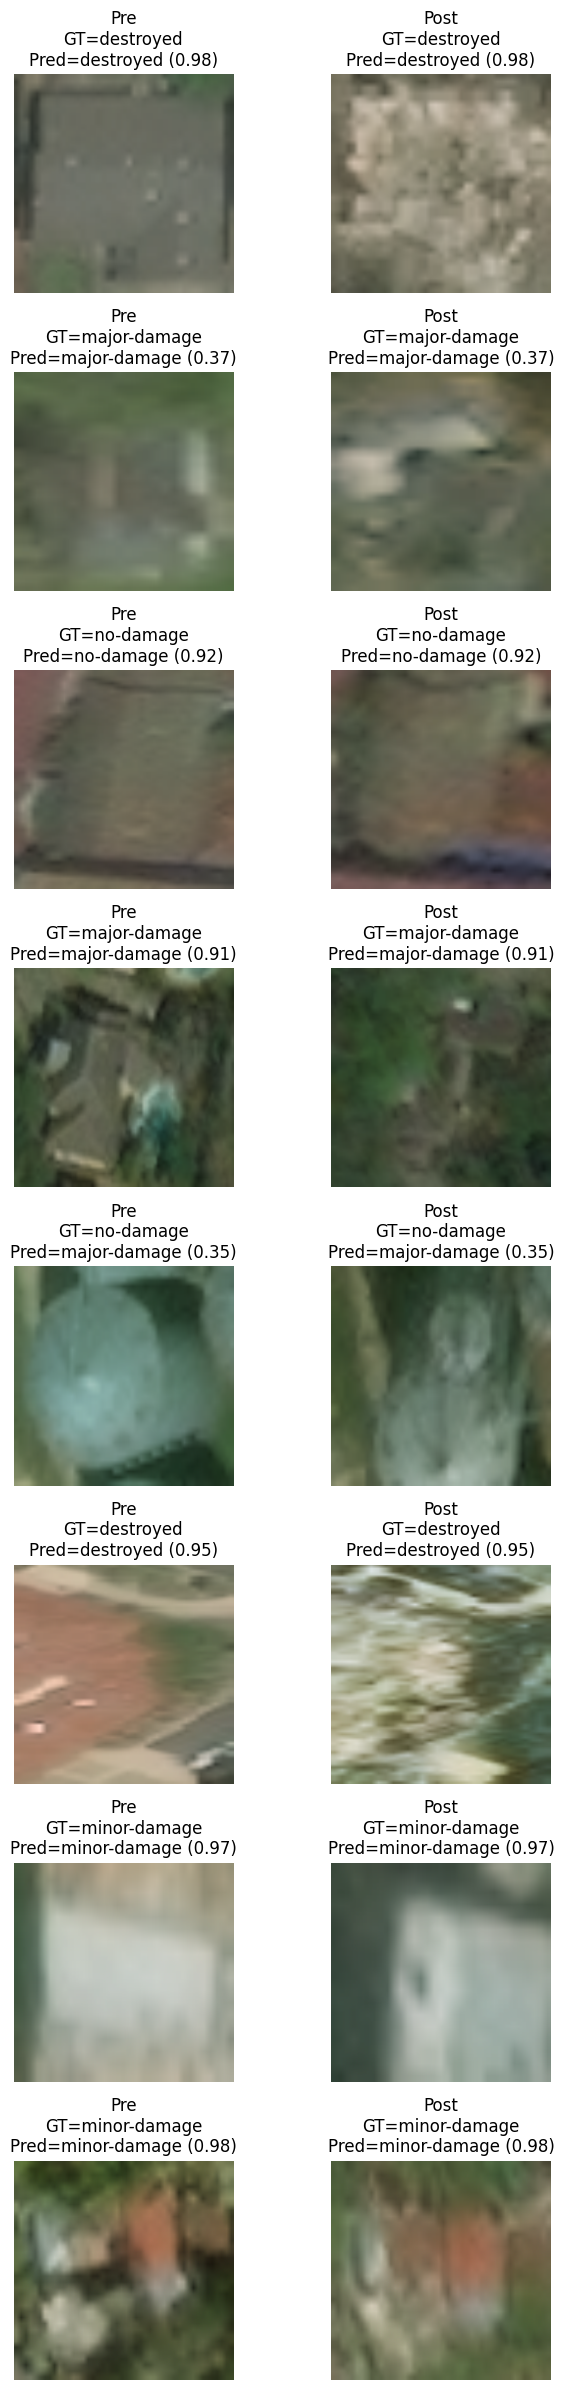

In [140]:
@torch.no_grad()
def qualitative_predictions(n: int = 8):
    checkpoint = CHECKPOINTS_DIR / "best_swin_tiny_damage.pt"
    if not checkpoint.exists() or test_loader is None:
        print("Need a trained Swin-Tiny checkpoint and test loader for qualitative predictions.")
        return
    model, _ = load_swin_checkpoint(checkpoint)
    dataset = test_loader.dataset
    indices = list(range(min(n, len(dataset))))
    fig, axes = plt.subplots(len(indices), 2, figsize=(7, 3 * len(indices)))
    if len(indices) == 1:
        axes = np.array([axes])
    inv_norm = transforms.Normalize(
        mean=[-m / s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)],
        std=[1 / s for s in IMAGENET_STD],
    )
    for row_idx, idx in enumerate(indices):
        pre, post, label, _ = dataset[idx]
        logits = model(pre.unsqueeze(0).to(device), post.unsqueeze(0).to(device))
        prob = torch.softmax(logits, dim=1)[0]
        conf, pred = prob.max(dim=0)
        for col, tensor, title_prefix in [(0, pre, "Pre"), (1, post, "Post")]:
            image = inv_norm(tensor).clamp(0, 1).permute(1, 2, 0).cpu().numpy()
            axes[row_idx, col].imshow(image)
            axes[row_idx, col].axis("off")
            axes[row_idx, col].set_title(
                f"{title_prefix}\nGT={ID_TO_DAMAGE[int(label)]}\nPred={ID_TO_DAMAGE[int(pred)]} ({float(conf):.2f})"
            )
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "qualitative_damage_predictions.png", dpi=200)
    plt.show()

qualitative_predictions()


## 13. SAM2-Assisted Full-Image Inference

This section uses SAM2 to produce building masks from prompts, converts masks to connected components, crops the same regions from pre/post images, and classifies each crop with Swin-Tiny.

You need a SAM2 config, a SAM2 checkpoint, and prompt points for the image. The exact prompt strategy can be manual, grid-based, or generated from another proposal method.


**Important prompt note:** SAM2 is prompt-based. It does not automatically know which objects are buildings. For meaningful damage prediction, the prompt must target a building region. A tight box around one visible building is usually more reliable than a single point.


RUN_SAM2_ALL_BUILDINGS_INFERENCE: True
RUN_SAM2_INFERENCE: False
Safe classification_report override is active.
Demo image ID: guatemala-volcano_00000003
Pre image: D:\Deeplearning project\test_data\test\images\guatemala-volcano_00000003_pre_disaster.png
Post image: D:\Deeplearning project\test_data\test\images\guatemala-volcano_00000003_post_disaster.png
Annotation: D:\Deeplearning project\test_data\test\labels\guatemala-volcano_00000003_post_disaster.json
Number of annotated buildings found: 3
Running SAM2 + Swin inference for 3 building annotation(s).


All buildings SAM2: 100%|██████████| 3/3 [00:00<00:00, 24.31it/s]


Saved all-buildings SAM2 prediction image to: D:\Deeplearning project\reports\figures\all_buildings_sam2_prediction.png
Saved all-buildings predictions CSV to: D:\Deeplearning project\reports\all_buildings_sam2_predictions.csv
              precision    recall  f1-score   support

   no-damage       0.00      0.00      0.00         0
minor-damage       1.00      0.50      0.67         2
major-damage       0.00      0.00      0.00         0
   destroyed       1.00      1.00      1.00         1

    accuracy                           0.67         3
   macro avg       0.50      0.38      0.42         3
weighted avg       1.00      0.67      0.78         3



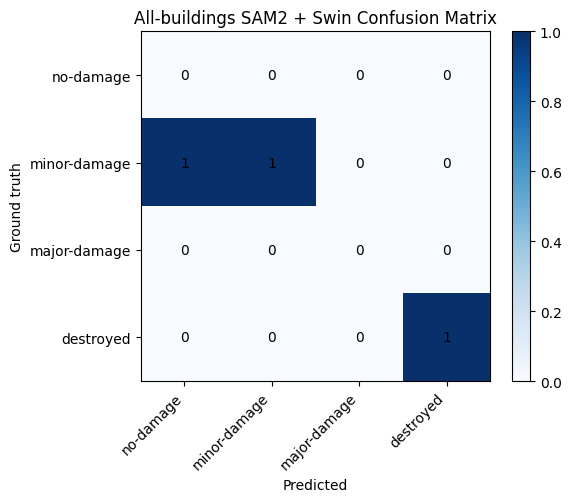

Saved confusion matrix to: D:\Deeplearning project\reports\figures\all_buildings_sam2_confusion_matrix.png

All-buildings inference finished.
Predictions shape: (3, 13)


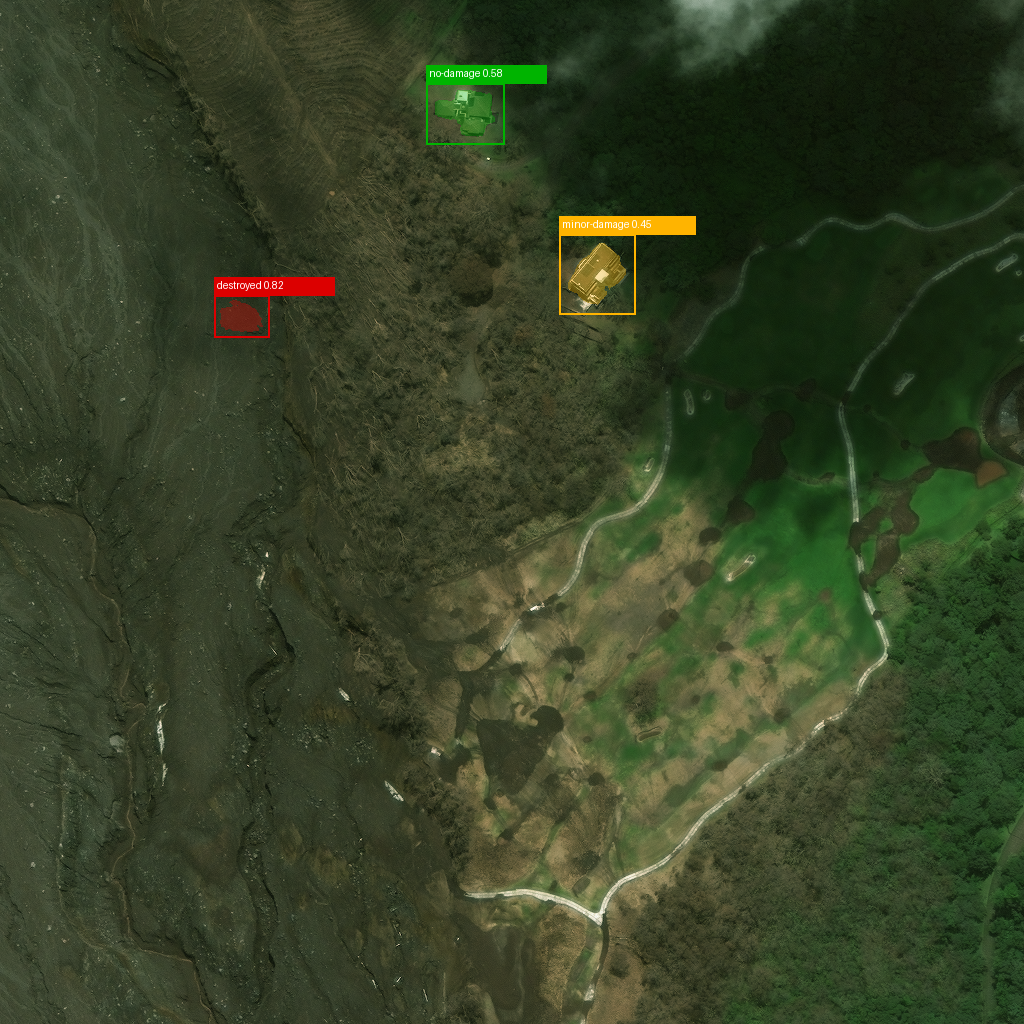

,building_id,x1,y1,x2,y2,predicted_label,confidence,sam2_score,no_damage_prob,minor_damage_prob,major_damage_prob,destroyed_prob,ground_truth_label
0,0,426,83,504,144,no-damage,0.576740,0.921544,0.576740,0.285114,0.092165,0.045980,minor-damage
1,1,214,295,269,337,destroyed,0.823351,0.679087,0.027210,0.054784,0.094655,0.823351,destroyed
2,2,559,234,635,314,minor-damage,0.446473,0.881479,0.234038,0.446473,0.245207,0.074283,minor-damage


Saved all-buildings SAM2 debug figure to: D:\Deeplearning project\reports\figures\all_buildings_sam2_debug.png


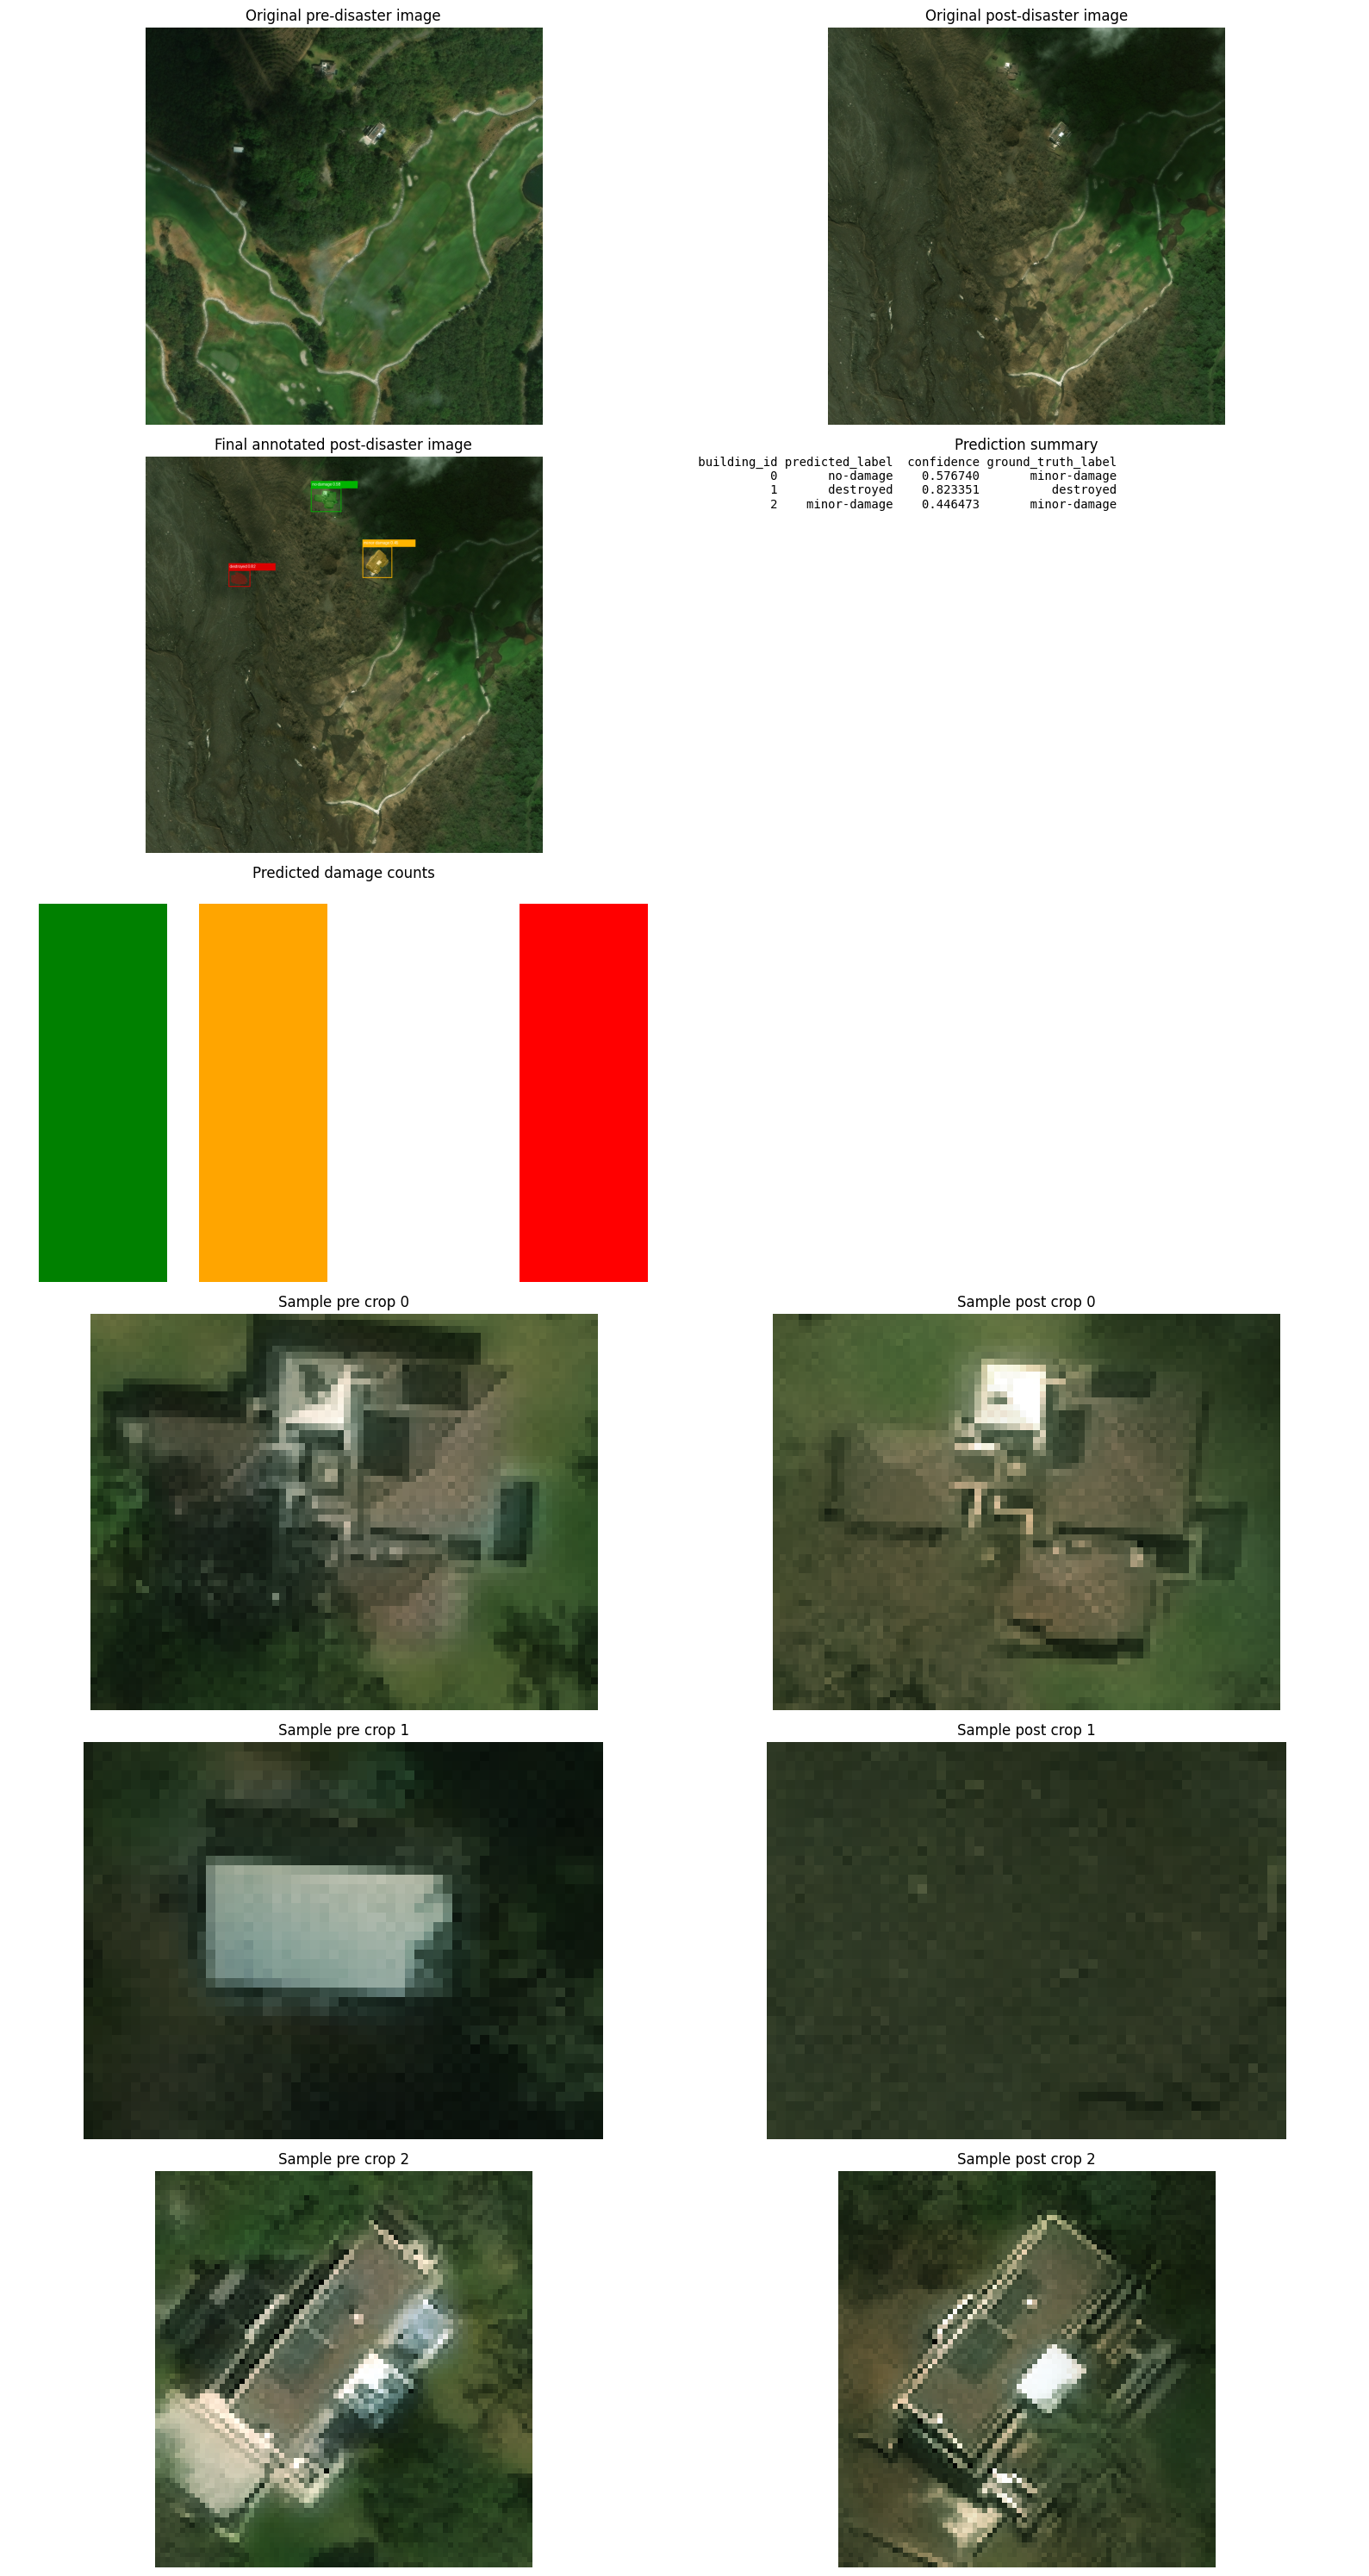

              precision    recall  f1-score   support

   no-damage       0.00      0.00      0.00         0
minor-damage       1.00      0.50      0.67         2
major-damage       0.00      0.00      0.00         0
   destroyed       1.00      1.00      1.00         1

    accuracy                           0.67         3
   macro avg       0.50      0.38      0.42         3
weighted avg       1.00      0.67      0.78         3

Saved classification report to: D:\Deeplearning project\reports\all_buildings_sam2_classification_report.txt


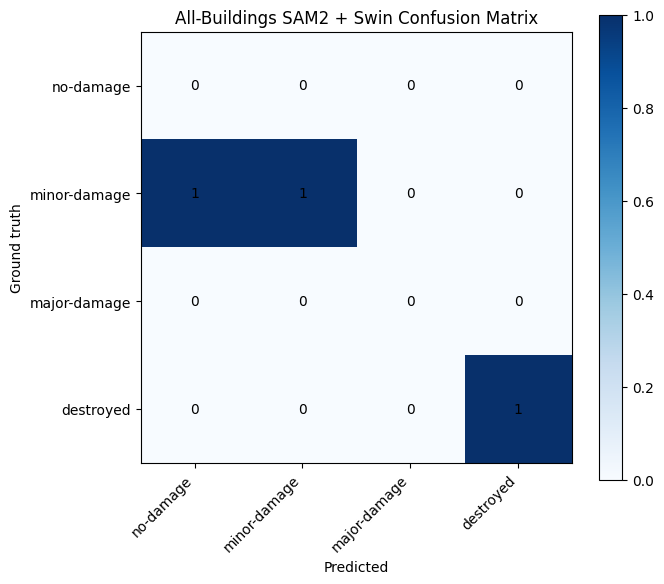

Saved safe confusion matrix to: D:\Deeplearning project\reports\figures\all_buildings_sam2_confusion_matrix_safe.png


In [165]:
# ============================================================
# SAFE ALL-BUILDINGS SAM2 INFERENCE RUNNER
# Fixes classification_report class-count error
# Runs all-buildings inference only
# Does NOT edit/retrain the CNN/Swin model
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    classification_report as sklearn_classification_report,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Disable the old single-building demo
# ------------------------------------------------------------

RUN_SAM2_ALL_BUILDINGS_INFERENCE = True
RUN_SAM2_INFERENCE = False

print("RUN_SAM2_ALL_BUILDINGS_INFERENCE:", RUN_SAM2_ALL_BUILDINGS_INFERENCE)
print("RUN_SAM2_INFERENCE:", RUN_SAM2_INFERENCE)


# ------------------------------------------------------------
# 2. Override classification_report safely
# ------------------------------------------------------------
# Your function calls classification_report with 4 target names.
# If the current image contains only 2 or 3 classes, sklearn raises:
# ValueError: Number of classes, 3, does not match size of target_names, 4
#
# This wrapper forces labels=[0,1,2,3], so all 4 damage classes are always included.
# ------------------------------------------------------------

def classification_report(
    y_true,
    y_pred,
    labels=None,
    target_names=None,
    zero_division=0,
    **kwargs
):
    if target_names is not None and labels is None:
        labels = list(range(len(target_names)))

    return sklearn_classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=target_names,
        zero_division=zero_division,
        **kwargs
    )


print("Safe classification_report override is active.")


# ------------------------------------------------------------
# 3. Optional: safer confusion-matrix plotting helper
# ------------------------------------------------------------

def safe_plot_all_buildings_confusion_matrix(predictions_df, save_path=None):
    damage_classes = _local_damage_classes()
    label_ids = list(range(len(damage_classes)))
    damage_to_id = _local_damage_to_id()

    eval_df = predictions_df.copy()

    if "ground_truth_label" not in eval_df.columns:
        print("No ground_truth_label column found. Skipping confusion matrix.")
        return None

    eval_df = eval_df.dropna(subset=["ground_truth_label", "predicted_label"])
    eval_df = eval_df[
        eval_df["ground_truth_label"].isin(damage_classes)
        & eval_df["predicted_label"].isin(damage_classes)
    ]

    if eval_df.empty:
        print("No valid ground-truth/prediction rows. Skipping confusion matrix.")
        return None

    y_true = eval_df["ground_truth_label"].map(damage_to_id).astype(int).tolist()
    y_pred = eval_df["predicted_label"].map(damage_to_id).astype(int).tolist()

    report_text = sklearn_classification_report(
        y_true,
        y_pred,
        labels=label_ids,
        target_names=damage_classes,
        zero_division=0,
    )

    report_path = REPORTS_DIR / "all_buildings_sam2_classification_report.txt"
    report_path.write_text(report_text, encoding="utf-8")
    print(report_text)
    print(f"Saved classification report to: {report_path}")

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=label_ids,
    )

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks(range(len(damage_classes)))
    ax.set_xticklabels(damage_classes, rotation=45, ha="right")

    ax.set_yticks(range(len(damage_classes)))
    ax.set_yticklabels(damage_classes)

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Ground truth")
    ax.set_title("All-Buildings SAM2 + Swin Confusion Matrix")

    for row_idx in range(cm.shape[0]):
        for col_idx in range(cm.shape[1]):
            ax.text(
                col_idx,
                row_idx,
                str(cm[row_idx, col_idx]),
                ha="center",
                va="center",
                color="black",
            )

    fig.colorbar(im, ax=ax)
    plt.tight_layout()

    if save_path is None:
        save_path = FIGURES_DIR / "all_buildings_sam2_confusion_matrix_safe.png"

    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plt.savefig(save_path, dpi=200)
    plt.show()

    print(f"Saved safe confusion matrix to: {save_path}")

    return cm


# ------------------------------------------------------------
# 4. Select image pair and annotation
# ------------------------------------------------------------

demo_pairs = match_pre_post_pairs(TEST_DIR / "images")

if not demo_pairs:
    raise RuntimeError("No test pre/post image pairs found.")

# Change this index if you want another image
DEMO_PAIR_INDEX = 0

pre_image_path, post_image_path, demo_image_id = demo_pairs[DEMO_PAIR_INDEX]

annotation_path = find_annotation_file(
    post_image_path,
    TEST_DIR / "labels",
    TEST_DIR / "targets",
    prefer_post=True,
)

if annotation_path is None:
    raise RuntimeError(f"No annotation found for {post_image_path}")

print("Demo image ID:", demo_image_id)
print("Pre image:", pre_image_path)
print("Post image:", post_image_path)
print("Annotation:", annotation_path)


# ------------------------------------------------------------
# 5. Check number of buildings before running SAM2
# ------------------------------------------------------------

post_img_for_size = Image.open(post_image_path).convert("RGB")
buildings = extract_buildings_from_xbd_json(annotation_path, post_img_for_size.size)

print("Number of annotated buildings found:", len(buildings))

if len(buildings) == 0:
    raise RuntimeError("No annotated buildings found. Check annotation parser/path.")


# ------------------------------------------------------------
# 6. Run all-buildings SAM2 inference
# ------------------------------------------------------------

annotated_img, predictions_df, debug_outputs = full_image_all_buildings_inference_with_sam2(
    pre_image_path=pre_image_path,
    post_image_path=post_image_path,
    annotation_path=annotation_path,
    classifier_checkpoint=CHECKPOINTS_DIR / "best_swin_tiny_damage.pt",
    output_path=FIGURES_DIR / "all_buildings_sam2_prediction.png",
    bbox_padding_ratio=0.15,
    use_masked_crops=False,
    min_box_area=50,
    max_box_area_ratio=0.05,
    max_buildings=None,  # set to 5 or 10 for quick testing
)

print("\nAll-buildings inference finished.")
print("Predictions shape:", predictions_df.shape)

display(annotated_img)
display(predictions_df.head(20))


# ------------------------------------------------------------
# 7. Save and show debug figure
# ------------------------------------------------------------

show_all_buildings_debug(
    debug_outputs,
    predictions_df,
    save_path=FIGURES_DIR / "all_buildings_sam2_debug.png",
)


# ------------------------------------------------------------
# 8. Run safe evaluation again if labels exist
# ------------------------------------------------------------

if "ground_truth_label" in predictions_df.columns:
    safe_plot_all_buildings_confusion_matrix(
        predictions_df,
        save_path=FIGURES_DIR / "all_buildings_sam2_confusion_matrix_safe.png",
    )
else:
    print("No ground_truth_label column found. Skipping safe evaluation.")

## 14. Technical Report Summary

### Dataset

The xView2/xBD dataset contains pre-disaster and post-disaster satellite image pairs with building polygons and ordinal building damage labels. The four damage labels are no-damage, minor-damage, major-damage, and destroyed.

### Preprocessing

The notebook matches pre/post image pairs, loads JSON annotations, parses building polygons, converts polygons to bounding boxes, clips invalid boxes, and saves paired building crops for supervised damage classification. Training uses ImageNet normalization and paired geometric augmentation so both crops remain aligned.

### Model Architecture

The final classifier is a dual-input Swin Transformer-Tiny pretrained on ImageNet. One shared Swin-Tiny backbone extracts features from the pre-disaster and post-disaster crops. The feature vector, post feature vector, and absolute feature difference are concatenated and passed to a small classification head.

### Localization

SAM2-assisted localization is used only at inference time when ground-truth xBD polygons are unavailable. SAM2 segments prompted building regions, connected components are converted into crop boxes, and each crop pair is classified by the already-trained Swin-Tiny checkpoint.

### Experiments and Results

The classifier has already been trained from xBD ground-truth crop pairs. SAM2 inference outputs are saved under reports/figures, including the full-pipeline mask, box, damage label, and confidence visualization.

### Limitations and Data Challenges

Damage classes are imbalanced, minor and major damage can be visually subtle, dense buildings can merge in masks, and post-disaster context can be ambiguous. SAM2 quality depends on the prompt strategy and checkpoint choice.

### Future Improvements

Future work can include automatic prompt generation, stronger crop sampling strategies, temporal attention between pre/post crops, disaster-specific augmentation, ensembling, geospatial metadata, and end-to-end multi-task training.
